In [1]:
import pandas as pd
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt

# Load data (replace with your dataset path)
df = pd.read_csv("LifeExpectancy.csv")

# Inspect dataset
df.head()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,...,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Country,Status
0,2015,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,...,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1,Afghanistan,Developing
1,2014,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,...,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0,Afghanistan,Developing
2,2013,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,...,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9,Afghanistan,Developing
3,2012,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,...,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8,Afghanistan,Developing
4,2011,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,...,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5,Afghanistan,Developing


In [10]:
df_dum = pd.get_dummies(df, columns=['Country', 'Status'], drop_first=True)


In [11]:
X = df_dum.drop("Life expectancy ", axis=1)
y = df_dum["Life expectancy "]

X = sm.add_constant(df_dum.drop('Life expectancy ', axis=1)).astype(float)
model_full = sm.OLS(y, X).fit()
model_full.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       Life expectancy    R-squared:                       0.964
Model:                            OLS   Adj. R-squared:                  0.961
Method:                 Least Squares   F-statistic:                     363.5
Date:                Thu, 27 Nov 2025   Prob (F-statistic):               0.00
Time:                        11:16:37   Log-Likelihood:                -5885.4
No. Observations:                2928   AIC:                         1.217e+04
Df Residuals:                    2726   BIC:                         1.338e+04
Df Model:                         201                                         
Covariance Type:            nonrobust                                         
================================================================================================================================
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------
const                                                         -443.7371     19.851    -22.353      0.000    -482.662    -404.813
Year                                                             0.2661      0.010     25.688      0.000       0.246       0.286
Adult Mortality                                                 -0.0019      0.000     -4.336      0.000      -0.003      -0.001
infant deaths                                                    0.0844      0.011      7.619      0.000       0.063       0.106
Alcohol                                                         -0.0627      0.023     -2.729      0.006      -0.108      -0.018
percentage expenditure                                           0.0001   4.95e-05      2.944      0.003    4.86e-05       0.000
Hepatitis B                                                     -0.0036      0.002     -1.753      0.080      -0.008       0.000
Measles                                                      -1.133e-05   4.31e-06     -2.629      0.009   -1.98e-05   -2.88e-06
 BMI                                                            -0.0031      0.003     -1.056      0.291      -0.009       0.003
under-five deaths                                               -0.0621      0.008     -8.028      0.000      -0.077      -0.047
Polio                                                            0.0048      0.002      2.156      0.031       0.000       0.009
Total expenditure                                               -0.0421      0.022     -1.906      0.057      -0.085       0.001
Diphtheria                                                       0.0064      0.002      2.658      0.008       0.002       0.011
 HIV/AIDS                                                       -0.3250      0.015    -21.705      0.000      -0.354      -0.296
GDP                                                          -1.966e-05   7.73e-06     -2.545      0.011   -3.48e-05   -4.51e-06
Population                                                   -5.729e-10   8.31e-10     -0.689      0.491    -2.2e-09    1.06e-09
 thinness  1-19 years                                            0.0183      0.028      0.659      0.510      -0.036       0.073
 thinness 5-9 years                                              0.0234      0.028      0.850      0.395      -0.031       0.077
Income composition of resources                                 -0.2244      0.425     -0.528      0.597      -1.057       0.608
Schooling                                                        0.1364      0.040      3.453      0.001       0.059       0.214
Country_Albania                                                 16.4538      0.795     20.692      0.000      14.895

now let's remove country

In [17]:
df_no_country = df.drop(["Country", "Status"], axis=1)


In [19]:
X2 = df_no_country.drop("Life expectancy ", axis=1)
y = df_no_country["Life expectancy "]

#X = sm.add_constant(df_dum.drop('Life expectancy ', axis=1)).astype(float)
X2 = sm.add_constant(X2).astype(float)
model_reduced = sm.OLS(y, X2).fit()
model_reduced.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       Life expectancy    R-squared:                       0.818
Model:                            OLS   Adj. R-squared:                  0.817
Method:                 Least Squares   F-statistic:                     689.2
Date:                Thu, 27 Nov 2025   Prob (F-statistic):               0.00
Time:                        11:54:33   Log-Likelihood:                -8256.7
No. Observations:                2928   AIC:                         1.655e+04
Df Residuals:                    2908   BIC:                         1.667e+04
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              87.1164     34.892      2.497      0.013      18.701     155.532
Year                               -0.0163      0.017     -0.937      0.349      -0.051       0.018
Adult Mortality                    -0.0202      0.001    -25.356      0.000      -0.022      -0.019
infant deaths                       0.0990      0.008     11.675      0.000       0.082       0.116
Alcohol                             0.1161      0.024      4.738      0.000       0.068       0.164
percentage expenditure              0.0001   8.49e-05      1.512      0.131   -3.81e-05       0.000
Hepatitis B                        -0.0133      0.004     -3.378      0.001      -0.021      -0.006
Measles                         -2.103e-05    7.7e-06     -2.730      0.006   -3.61e-05   -5.92e-06
 BMI                                0.0431      0.005      8.627      0.000       0.033       0.053
under-five deaths                  -0.0739      0.006    -11.896      0.000      -0.086      -0.062
Polio                               0.0289      0.004      6.419      0.000       0.020       0.038
Total expenditure                   0.0825      0.034      2.394      0.017       0.015       0.150
Diphtheria                          0.0400      0.005      8.445      0.000       0.031       0.049
 HIV/AIDS                          -0.4733      0.018    -26.665      0.000      -0.508      -0.438
GDP                              3.716e-05   1.31e-05      2.842      0.005    1.15e-05    6.28e-05
Population                       7.459e-11    1.7e-09      0.044      0.965   -3.26e-09    3.41e-09
 thinness  1-19 years              -0.0822      0.051     -1.623      0.105      -0.182       0.017
 thinness 5-9 years                -0.0006      0.050     -0.011      0.991      -0.098       0.097
Income composition of resources     5.9095      0.647      9.132      0.000       4.641       7.178
Schooling                           0.6896      0.043     16.115      0.000       0.606       0.773
==============================================================================
Omnibus:                      137.552   Durbin-Watson:                   0.710
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              408.264
Skew:                          -0.175   Prob(JB):                     2.22e-89
Kurtosis:                       4.796   Cond. No.                     2.57e+10
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.57e+10. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

###part 2

In [24]:
# === Imports ===
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# === 1. Load data ===
# Change the path if your CSV is elsewhere
df = pd.read_csv("LifeExpectancy.csv")

# The column is usually called "Life expectancy " with a trailing space.
# This line makes sure we have a clean name to work with.
df = df.rename(columns={
    "Life expectancy ": "Life_exp",
    "Life expectancy": "Life_exp"  # in case your file has no trailing space
})

In [25]:
# === 2. Select 5 countries from different continents ===
# (You can change these if you want different ones.)
countries = ["Afghanistan",  # Asia
             "Albania",      # Europe
             "Algeria",      # Africa
             "Argentina",    # South America
             "Australia"]    # Oceania

df_sel = df[df["Country"].isin(countries)].copy()

# Optional: check that they’re there
print("Countries in subset:", df_sel["Country"].unique())
print()


Countries in subset: ['Afghanistan' 'Albania' 'Algeria' 'Argentina' 'Australia']



In [26]:
# === 3. One-way ANOVA: Does life expectancy differ among the 5 countries? ===
model = ols("Life_exp ~ C(Country)", data=df_sel).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print("=== ANOVA table ===")
print(anova_table)
print()

# Interpretation hint:
# If PR(>F) < 0.05 → significant difference in life expectancy
p_value = anova_table["PR(>F)"][0]
print(f"ANOVA p-value: {p_value:.4e}")
if p_value < 0.05:
    print("=> Significant difference in life expectancy between countries.\n")
else:
    print("=> No significant difference in life expectancy between countries.\n")

=== ANOVA table ===
               sum_sq    df           F        PR(>F)
C(Country)  4901.4575   4.0  423.727826  1.212749e-50
Residual     216.8900  75.0         NaN           NaN

ANOVA p-value: 1.2127e-50
=> Significant difference in life expectancy between countries.



C:\Users\Utente\AppData\Local\Temp\ipykernel_14980\3949210690.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_value = anova_table["PR(>F)"][0]


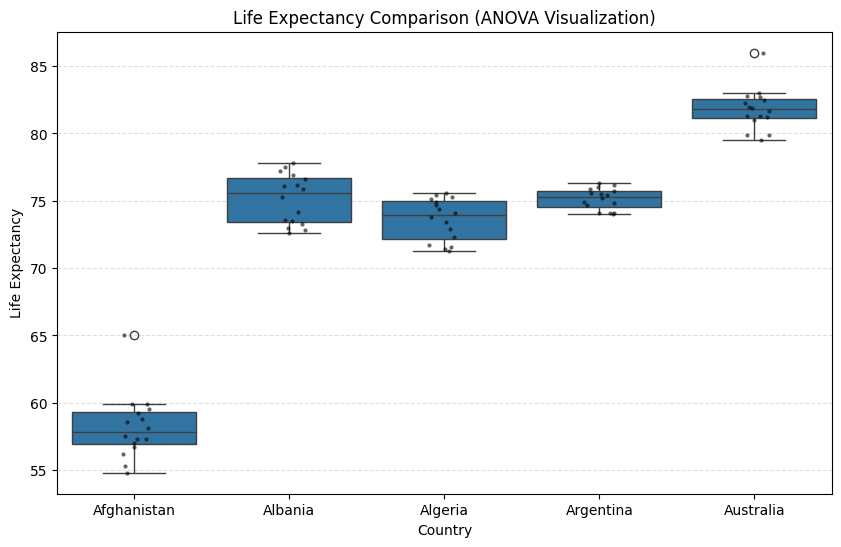

In [28]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_sel, x="Country", y="Life_exp")
sns.stripplot(data=df_sel, x="Country", y="Life_exp", color="black", size=3, alpha=0.6)

plt.title("Life Expectancy Comparison (ANOVA Visualization)")
plt.ylabel("Life Expectancy")
plt.xlabel("Country")
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

In [31]:
# === 4. Post-hoc test (Tukey HSD) ===
# Only meaningful if ANOVA is significant.
tukey = pairwise_tukeyhsd(
    endog=df_sel["Life_exp"],       # dependent variable
    groups=df_sel["Country"],       # group variable
    alpha=0.05                      # significance level
)

print("=== Tukey HSD post-hoc results ===")
tukey.summary()

=== Tukey HSD post-hoc results ===


group1,group2,meandiff,p-adj,lower,upper,reject
Afghanistan,Albania,16.9625,0.0,15.2819,18.6431,True
Afghanistan,Algeria,15.425,0.0,13.7444,17.1056,True
Afghanistan,Argentina,16.9625,0.0,15.2819,18.6431,True
Afghanistan,Australia,23.6188,0.0,21.9381,25.2994,True
Albania,Algeria,-1.5375,0.0891,-3.2181,0.1431,False
Albania,Argentina,0.0,1.0,-1.6806,1.6806,False
Albania,Australia,6.6563,0.0,4.9756,8.3369,True
Algeria,Argentina,1.5375,0.0891,-0.1431,3.2181,False
Algeria,Australia,8.1938,0.0,6.5131,9.8744,True
Argentina,Australia,6.6563,0.0,4.9756,8.3369,True


In [32]:
# Optional: show group means to interpret differences
print("=== Mean life expectancy by country ===")
df_sel.groupby("Country")["Life_exp"].mean()

=== Mean life expectancy by country ===


Country
Afghanistan    58.19375
Albania        75.15625
Algeria        73.61875
Argentina      75.15625
Australia      81.81250
Name: Life_exp, dtype: float64